In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Bio import SeqIO
from pathlib import Path
from PIL import Image
from itertools import product
from collections import Counter

import cv2

In [102]:
FASTA_FILE = r"C:\Users\Kru\Downloads\Melocanna.fasta"

In [103]:
K = 4

WINDOW_SIZE = 1000

STEP_SIZE = 250

QUALITY_THRESHOLD = 0.95

MAX_IMAGES = 100

NUMBER_OF_SELECTED_KMERS = 500

In [104]:
OUTPUT_DIR = Path(
    "Melocanna_fasta_fcgr_output"
)

IMAGE_DIR = (
    OUTPUT_DIR /
    "fcgr_images"
)

OUTPUT_DIR.mkdir(
    exist_ok=True
)

IMAGE_DIR.mkdir(
    exist_ok=True
)

In [105]:
NUCLEOTIDE_COLORS = {

    "A": np.array(
        [1.0, 0.0, 0.0]
    ),

    "C": np.array(
        [0.0, 0.0, 1.0]
    ),

    "G": np.array(
        [0.0, 1.0, 0.0]
    ),

    "T": np.array(
        [1.0, 1.0, 0.0]
    )
}

In [106]:
records = list(
    SeqIO.parse(
        FASTA_FILE,
        "fasta"
    )
)


if len(records) == 0:

    raise ValueError(
        "No FASTA sequence was found."
    )


# Use first FASTA record

record = records[0]

sequence = str(
    record.seq
).upper()


In [107]:
print(
    "\n=========================================="
)

print(
    "FASTA INFORMATION"
)

print(
    "=========================================="
)


print(
    "Genome ID:",
    record.id
)


print(
    "Original Genome length:",
    len(sequence)
)


original_n_count = sequence.count(
    "N"
)


print(
    "Original Number of N:",
    original_n_count
)


original_n_percentage = (
    original_n_count /
    len(sequence)
) * 100


print(
    "Original N percentage:",
    round(
        original_n_percentage,
        4
    ),
    "%"
)


FASTA INFORMATION
Genome ID: JAYEVJ010000043.1
Original Genome length: 100000
Original Number of N: 0
Original N percentage: 0.0 %


In [108]:
sequence = "".join(

    base if base in "ACGTN"
    else "N"

    for base in sequence
)


print(
    "\n=========================================="
)

print(
    "DNA PREPROCESSING"
)

print(
    "=========================================="
)


print(
    "Processed genome length:",
    len(sequence)
)


print(
    "Number of N after preprocessing:",
    sequence.count("N")
)


DNA PREPROCESSING
Processed genome length: 100000
Number of N after preprocessing: 0


In [109]:
def window_quality(window):

    valid_bases = sum(

        base in "ACGT"

        for base in window

    )

    return (
        valid_bases /
        len(window)
    )

In [110]:
windows = []


for start in range(
    0,
    len(sequence),
    STEP_SIZE
):

    # Maximum number of windows

    if len(windows) >= MAX_IMAGES:

        break


    # Extract window

    window = sequence[
        start:
        start + WINDOW_SIZE
    ]


    # Ignore incomplete final window

    if len(window) < WINDOW_SIZE:

        break


    # Calculate quality

    quality = window_quality(
        window
    )


    # Keep only good-quality windows

    if quality >= QUALITY_THRESHOLD:

        windows.append({

            "window_number":
                len(windows) + 1,

            "start":
                start,

            "end":
                start + WINDOW_SIZE,

            "sequence":
                window,

            "quality":
                quality

        })



In [111]:
print(
    "\n=========================================="
)

print(
    "WINDOW QUALITY CONTROL"
)

print(
    "=========================================="
)


print(
    "Window size:",
    WINDOW_SIZE
)


print(
    "Step size:",
    STEP_SIZE
)


print(
    "Quality threshold:",
    QUALITY_THRESHOLD
)


print(
    "Maximum windows:",
    MAX_IMAGES
)


print(
    "Total good windows:",
    len(windows)
)


if len(windows) == 0:

    raise ValueError(
        "No windows passed the quality threshold."
    )


WINDOW QUALITY CONTROL
Window size: 1000
Step size: 250
Quality threshold: 0.95
Maximum windows: 100
Total good windows: 100


In [112]:
def generate_all_kmers(k):

    return [

        ''.join(kmer)

        for kmer in product(
            "ACGT",
            repeat=k
        )

    ]


all_kmers = generate_all_kmers(
    K
)



In [113]:
print(
    "\n=========================================="
)

print(
    "K-MER INFORMATION"
)

print(
    "=========================================="
)


print(
    "K-mer size:",
    K
)


print(
    "Total possible k-mers:",
    len(all_kmers)
)


print(
    "Expected for K=4:",
    4 ** K
)




K-MER INFORMATION
K-mer size: 4
Total possible k-mers: 256
Expected for K=4: 256


In [114]:
def get_kmer_counts(
    sequence,
    k
):

    counts = {}


    for i in range(
        len(sequence) - k + 1
    ):

        kmer = sequence[
            i:
            i + k
        ]


        # Ignore k-mers containing N

        if all(

            base in "ACGT"

            for base in kmer

        ):

            counts[kmer] = (

                counts.get(
                    kmer,
                    0
                )

                + 1

            )


    return counts


In [115]:
def get_kmer_frequency_vector(
    sequence,
    k,
    all_kmers
):

    counts = get_kmer_counts(
        sequence,
        k
    )


    total_kmers = sum(
        counts.values()
    )


    if total_kmers == 0:

        return np.zeros(

            len(all_kmers),

            dtype=np.float32

        )


    vector = np.array(

        [

            counts.get(
                kmer,
                0
            )

            / total_kmers

            for kmer in all_kmers

        ],

        dtype=np.float32

    )


    return vector

In [116]:
X_kmer = []


for window_data in windows:

    vector = get_kmer_frequency_vector(

        window_data["sequence"],

        K,

        all_kmers

    )

    X_kmer.append(
        vector
    )


X_kmer = np.array(

    X_kmer,

    dtype=np.float32

)

In [117]:
print(
    "\n=========================================="
)

print(
    "K-MER FEATURE MATRIX"
)

print(
    "=========================================="
)


print(
    "Matrix shape:",
    X_kmer.shape
)


print(
    "Rows = DNA windows"
)


print(
    "Columns = k-mer features"
)



K-MER FEATURE MATRIX
Matrix shape: (100, 256)
Rows = DNA windows
Columns = k-mer features


In [118]:
kmer_frequency_df = pd.DataFrame(

    X_kmer,

    columns=all_kmers

)


kmer_frequency_df.insert(

    0,

    "window",

    [

        w["window_number"]

        for w in windows

    ]

)


kmer_frequency_df.insert(

    1,

    "start_position",

    [

        w["start"]

        for w in windows

    ]

)


kmer_frequency_df.insert(

    2,

    "quality",

    [

        w["quality"]

        for w in windows

    ]

)


kmer_frequency_df.to_csv(

    OUTPUT_DIR /
    "kmer_frequency_matrix.csv",

    index=False

)


In [119]:
print(
    "\n=========================================="
)

print(
    "VARIANCE-BASED FEATURE SELECTION"
)

print(
    "=========================================="
)


kmer_variances = np.var(

    X_kmer,

    axis=0

)


feature_selection_df = pd.DataFrame({

    "kmer":
        all_kmers,

    "variance":
        kmer_variances

})


feature_selection_df = (

    feature_selection_df

    .sort_values(

        by="variance",

        ascending=False

    )

    .reset_index(

        drop=True

    )

)



VARIANCE-BASED FEATURE SELECTION


In [120]:
number_to_select = min(

    NUMBER_OF_SELECTED_KMERS,

    len(all_kmers)

)


selected_kmers = (

    feature_selection_df

    .head(
        number_to_select
    )

    ["kmer"]

    .tolist()

)


print(
    "Original features:",
    len(all_kmers)
)


print(
    "Selected features:",
    len(selected_kmers)
)


print(
    "\nTop 20 selected k-mers:"
)


print(
    feature_selection_df.head(
        20
    )
)

Original features: 256
Selected features: 256

Top 20 selected k-mers:
    kmer  variance
0   AAAA  0.000102
1   TTTT  0.000062
2   ATAT  0.000060
3   AAAT  0.000050
4   ATTT  0.000043
5   AATT  0.000039
6   TGTG  0.000038
7   TATA  0.000038
8   CTCT  0.000031
9   TGGT  0.000029
10  CGCC  0.000029
11  CCTC  0.000029
12  TTTA  0.000029
13  TTAT  0.000026
14  TAAA  0.000025
15  TATT  0.000025
16  CTCC  0.000023
17  TTAA  0.000023
18  CAAA  0.000022
19  TCTC  0.000021


In [121]:
feature_selection_df.to_csv(

    OUTPUT_DIR /
    "all_kmer_variance_scores.csv",

    index=False

)

In [122]:
selected_kmer_df = (

    feature_selection_df

    .head(
        number_to_select
    )

)


selected_kmer_df.to_csv(

    OUTPUT_DIR /
    "selected_kmers.csv",

    index=False

)

In [123]:
kmer_to_index = {

    kmer: index

    for index, kmer

    in enumerate(
        all_kmers
    )

}


selected_indices = [

    kmer_to_index[kmer]

    for kmer in selected_kmers

]

In [124]:
X_selected = X_kmer[

    :,

    selected_indices

]


print(
    "\n=========================================="
)

print(
    "FEATURE REDUCTION"
)

print(
    "=========================================="
)


print(
    "Original matrix:",
    X_kmer.shape
)


print(
    "Reduced matrix:",
    X_selected.shape
)




FEATURE REDUCTION
Original matrix: (100, 256)
Reduced matrix: (100, 256)


In [125]:
selected_feature_matrix = pd.DataFrame(

    X_selected,

    columns=selected_kmers

)


selected_feature_matrix.insert(

    0,

    "window",

    [

        w["window_number"]

        for w in windows

    ]

)


selected_feature_matrix.insert(

    1,

    "start_position",

    [

        w["start"]

        for w in windows

    ]

)


selected_feature_matrix.insert(

    2,

    "quality",

    [

        w["quality"]

        for w in windows

    ]

)


selected_feature_matrix.to_csv(

    OUTPUT_DIR /
    "selected_kmer_feature_matrix.csv",

    index=False

)

In [126]:
def calculate_fcgr_coordinates(

    k,
    all_kmers

):

    size = 2 ** k

    coordinates = {}


    for kmer in all_kmers:

        x = 0.5

        y = 0.5


        for base in kmer:

            if base == "A":

                vertex = (
                    0,
                    1
                )

            elif base == "C":

                vertex = (
                    0,
                    0
                )

            elif base == "G":

                vertex = (
                    1,
                    0
                )

            elif base == "T":

                vertex = (
                    1,
                    1
                )


            x = (

                x +
                vertex[0]

            ) / 2


            y = (

                y +
                vertex[1]

            ) / 2


        row = int(

            y *
            (size - 1)

        )


        col = int(

            x *
            (size - 1)

        )


        coordinates[kmer] = (

            row,

            col

        )


    return coordinates


fcgr_coordinates = calculate_fcgr_coordinates(

    K,

    all_kmers

)


In [127]:
# ============================================================
# WEIGHTED + SATURATED COLORED FCGR
# ============================================================
#
# PURE BASE COLORS
#
# A = RED
# C = BLUE
# G = GREEN
# T = YELLOW
#
# PURE K-MERS:
# AAAAAA -> RED
# CCCCCC -> BLUE
# GGGGGG -> GREEN
# TTTTTT -> YELLOW
#
# MIXED K-MERS:
# AC -> mixture of A + C
# AG -> mixture of A + G
# AT -> mixture of A + T
# ACGTAC -> mixture of A + C + G + T
#
# POSITION  -> identifies the exact k-mer
# COLOR     -> nucleotide composition
# BRIGHTNESS -> k-mer frequency
# ============================================================


def generate_colored_fcgr(
    sequence,
    k,
    all_kmers,
    coordinates
):

    size = 2 ** k

    color_matrix = np.zeros(
        (size, size, 3),
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Count k-mers
    # --------------------------------------------------------

    kmer_counts = get_kmer_counts(
        sequence,
        k
    )

    total_kmers = sum(
        kmer_counts.values()
    )

    if total_kmers == 0:
        return color_matrix

    # --------------------------------------------------------
    # Process every possible k-mer
    # --------------------------------------------------------

    for kmer in all_kmers:

        count = kmer_counts.get(
            kmer,
            0
        )

        # If this k-mer does not occur,
        # leave its pixel black.
        if count == 0:
            continue

        row, col = coordinates[kmer]

        # ====================================================
        # 1. FIND NUCLEOTIDE COMPOSITION
        # ====================================================

        base_counts = Counter(kmer)

        A_fraction = (
            base_counts.get("A", 0) / k
        )

        C_fraction = (
            base_counts.get("C", 0) / k
        )

        G_fraction = (
            base_counts.get("G", 0) / k
        )

        T_fraction = (
            base_counts.get("T", 0) / k
        )

        # ====================================================
        # 2. ORIGINAL BASE COLORS
        # ====================================================

        A_color = np.array(
            [1.0, 0.0, 0.0]
        )   # RED

        C_color = np.array(
            [0.0, 0.0, 1.0]
        )   # BLUE

        G_color = np.array(
            [0.0, 1.0, 0.0]
        )   # GREEN

        T_color = np.array(
            [1.0, 1.0, 0.0]
        )   # YELLOW

        # ====================================================
        # 3. MIX THE COLORS ACCORDING TO BASE COMPOSITION
        # ====================================================

        mixed_color = (

            A_fraction * A_color

            +

            C_fraction * C_color

            +

            G_fraction * G_color

            +

            T_fraction * T_color
        )

        # ====================================================
        # 4. PRESERVE COLOR SATURATION
        # ====================================================
        #
        # Without this step, combinations such as
        # A + C + G + T can become dull/gray.
        #
        # We normalize by the strongest RGB channel.
        #
        # This preserves the color mixture while making
        # the result more visible.
        #
        # ====================================================

        max_channel = mixed_color.max()

        if max_channel > 0:

            mixed_color = (
                mixed_color /
                max_channel
            )

        # ====================================================
        # 5. FREQUENCY → BRIGHTNESS
        # ====================================================
        #
        # Color tells us composition.
        #
        # Brightness tells us how frequently the k-mer
        # occurs.
        #
        # sqrt is used so low-frequency k-mers remain visible.
        #
        # ====================================================

        frequency = (
            count /
            total_kmers
        )

        brightness = np.sqrt(
            frequency
        )

        # ====================================================
        # 6. APPLY BRIGHTNESS
        # ====================================================

        final_color = (
            mixed_color *
            brightness
        )

        # ====================================================
        # 7. STORE PIXEL
        # ====================================================

        color_matrix[
            row,
            col
        ] = final_color

    # ========================================================
    # 8. GLOBAL NORMALIZATION
    # ========================================================

    max_value = color_matrix.max()

    if max_value > 0:

        color_matrix = (
            color_matrix /
            max_value
        )

    return color_matrix

In [128]:
def preprocess_fcgr(fcgr):

    # --------------------------------------------------------
    # Convert 0-1 to 0-255
    # --------------------------------------------------------

    image = np.clip(

        fcgr * 255,

        0,

        255

    ).astype(
        np.uint8
    )


    # --------------------------------------------------------
    # Keep weak FCGR pixels
    # --------------------------------------------------------

    image = np.where(

        image > 1,

        image,

        0

    ).astype(
        np.uint8
    )


    # --------------------------------------------------------
    # Convert back to 0-1
    # --------------------------------------------------------

    processed = (

        image.astype(
            np.float32
        )

        /

        255.0

    )


    return processed


# ============================================================
# 29. IMAGE FEATURE EXTRACTION
# ============================================================

def extract_image_features(image):

    image_uint8 = np.clip(

        image * 255,

        0,

        255

    ).astype(
        np.uint8
    )


    features = {}


    # ========================================================
    # RGB STATISTICS
    # ========================================================

    for i, name in enumerate(

        ["R", "G", "B"]

    ):

        channel = image[

            :,

            :,

            i

        ]


        features[

            name + "_mean"

        ] = np.mean(
            channel
        )


        features[

            name + "_std"

        ] = np.std(
            channel
        )


        features[

            name + "_max"

        ] = np.max(
            channel
        )


        features[

            name + "_min"

        ] = np.min(
            channel
        )


    # ========================================================
    # GRAYSCALE
    # ========================================================

    gray = cv2.cvtColor(

        image_uint8,

        cv2.COLOR_RGB2GRAY

    )


    features[

        "gray_mean"

    ] = np.mean(
        gray
    )


    features[

        "gray_std"

    ] = np.std(
        gray
    )


    # ========================================================
    # EDGE DENSITY
    # ========================================================

    edges = cv2.Canny(

        gray,

        50,

        150

    )


    features[

        "edge_density"

    ] = np.mean(

        edges > 0

    )


    # ========================================================
    # ACTIVE PIXEL RATIO
    # ========================================================

    features[

        "active_pixel_ratio"

    ] = np.mean(

        gray > 10

    )


    # ========================================================
    # ENTROPY
    # ========================================================

    histogram = cv2.calcHist(

        [gray],

        [0],

        None,

        [256],

        [0, 256]

    )


    histogram = histogram.flatten()


    probability = (

        histogram

        /

        (

            histogram.sum()

            +

            1e-10

        )

    )


    entropy = -np.sum(

        probability

        *

        np.log2(

            probability

            +

            1e-10

        )

    )


    features[

        "entropy"

    ] = entropy


    # ========================================================
    # NUCLEOTIDE COLOR RATIOS
    # ========================================================

    red_pixels = (

        (image_uint8[:, :, 0] > 100)

        &

        (image_uint8[:, :, 1] < 100)

        &

        (image_uint8[:, :, 2] < 100)

    )


    blue_pixels = (

        (image_uint8[:, :, 2] > 100)

        &

        (image_uint8[:, :, 0] < 100)

        &

        (image_uint8[:, :, 1] < 100)

    )


    green_pixels = (

        (image_uint8[:, :, 1] > 100)

        &

        (image_uint8[:, :, 0] < 100)

        &

        (image_uint8[:, :, 2] < 100)

    )


    yellow_pixels = (

        (image_uint8[:, :, 0] > 100)

        &

        (image_uint8[:, :, 1] > 100)

        &

        (image_uint8[:, :, 2] < 100)

    )


    features[

        "A_ratio"

    ] = np.mean(
        red_pixels
    )


    features[

        "C_ratio"

    ] = np.mean(
        blue_pixels
    )


    features[

        "G_ratio"

    ] = np.mean(
        green_pixels
    )


    features[

        "T_ratio"

    ] = np.mean(
        yellow_pixels
    )


    return features



In [129]:
image_feature_rows = []

image_files = []


print(
    "\n=========================================="
)

print(
    "GENERATING FCGR IMAGES"
)

print(
    "=========================================="
)


for index, window_data in enumerate(

    windows

):


    print(

        f"Processing window "

        f"{index + 1}/{len(windows)}"

    )


    window_sequence = (

        window_data["sequence"]

    )


    # ========================================================
    # IMPORTANT:
    #
    # FCGR uses ALL 4096 K-MERS
    #
    # The 500 selected k-mers are NOT removed from the
    # feature-selection CSVs.
    # ========================================================

    fcgr = generate_colored_fcgr(

        window_sequence,

        K,

        all_kmers,

        fcgr_coordinates

    )


    # ========================================================
    # IMAGE PREPROCESSING
    # ========================================================

    processed_fcgr = preprocess_fcgr(

        fcgr

    )


    # ========================================================
    # IMAGE FEATURES
    # ========================================================

    image_features = extract_image_features(

        processed_fcgr

    )


    # ========================================================
    # WINDOW INFORMATION
    # ========================================================

    feature_row = {

        "window":
            window_data[
                "window_number"
            ],

        "start_position":
            window_data[
                "start"
            ],

        "end_position":
            window_data[
                "end"
            ],

        "quality":
            window_data[
                "quality"
            ]

    }


    feature_row.update(

        image_features

    )


    image_feature_rows.append(

        feature_row

    )


    # ========================================================
    # CONVERT IMAGE TO UINT8
    # ========================================================

    image_array = np.clip(

        processed_fcgr * 255,

        0,

        255

    ).astype(
        np.uint8
    )


        # ========================================================
    # CREATE IMAGE AND REMOVE BLACK STRIP
    # ========================================================

    image = Image.fromarray(image_array)

    # Find the actual FCGR content boundaries
    non_black_pixels = np.any(image_array > 0, axis=2)

    rows = np.where(np.any(non_black_pixels, axis=1))[0]
    cols = np.where(np.any(non_black_pixels, axis=0))[0]

    if len(rows) > 0 and len(cols) > 0:

        top = rows[0]
        bottom = rows[-1] + 1
        left = cols[0]
        right = cols[-1] + 1

        # Remove unwanted black border
        image = image.crop(
            (left, top, right, bottom)
        )

    # ========================================================
    # RESIZE TO 512 × 512
    # ========================================================

    image = image.resize(
        (512, 512),
        Image.Resampling.NEAREST
    )
        # ========================================================
    # IMAGE FILE NAME
    # ========================================================

    image_filename = (
        f"FCGR_window_"
        f"{index + 1:04d}_"
        f"pos_"
        f"{window_data['start']}"
        ".png"
    )

    # ========================================================
    # SAVE IMAGE
    # ========================================================

    IMAGE_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    image_path = (
        IMAGE_DIR.resolve() / image_filename
    )

    image.save(
        str(image_path),
        format="PNG"
    )

    image_files.append(
        image_path
    )






GENERATING FCGR IMAGES
Processing window 1/100


Processing window 2/100
Processing window 3/100
Processing window 4/100
Processing window 5/100
Processing window 6/100
Processing window 7/100
Processing window 8/100
Processing window 9/100
Processing window 10/100
Processing window 11/100
Processing window 12/100
Processing window 13/100
Processing window 14/100
Processing window 15/100
Processing window 16/100
Processing window 17/100
Processing window 18/100
Processing window 19/100
Processing window 20/100
Processing window 21/100
Processing window 22/100
Processing window 23/100
Processing window 24/100
Processing window 25/100
Processing window 26/100
Processing window 27/100
Processing window 28/100
Processing window 29/100
Processing window 30/100
Processing window 31/100
Processing window 32/100
Processing window 33/100
Processing window 34/100
Processing window 35/100
Processing window 36/100
Processing window 37/100
Processing window 38/100
Processing window 39/100
Processing window 40/100
Processing window 41/100
Processi

In [130]:
image_features_df = pd.DataFrame(

    image_feature_rows

)


image_features_df.to_csv(

    OUTPUT_DIR /

    "image_features.csv",

    index=False

)


In [131]:
window_information = pd.DataFrame({

    "window":

        [

            w["window_number"]

            for w in windows

        ],

    "start_position":

        [

            w["start"]

            for w in windows

        ],

    "end_position":

        [

            w["end"]

            for w in windows

        ],

    "quality":

        [

            w["quality"]

            for w in windows

        ]

})


window_information.to_csv(

    OUTPUT_DIR /

    "window_information.csv",

    index=False

)




DISPLAYING FIRST 5 FCGR IMAGES


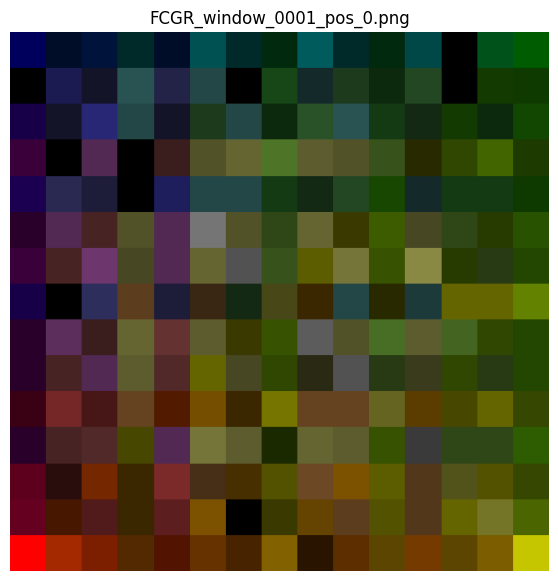

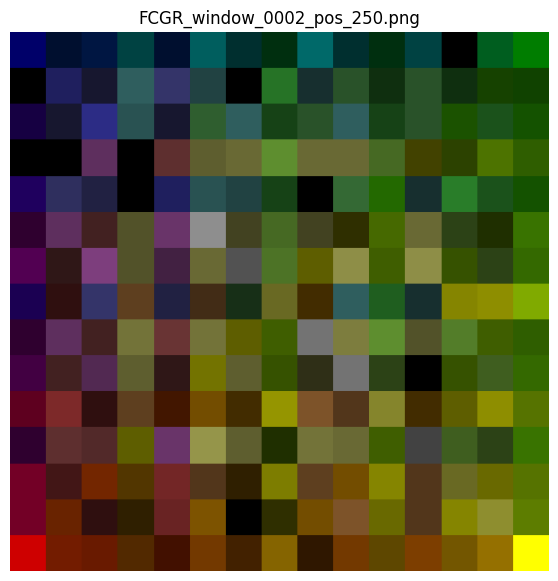

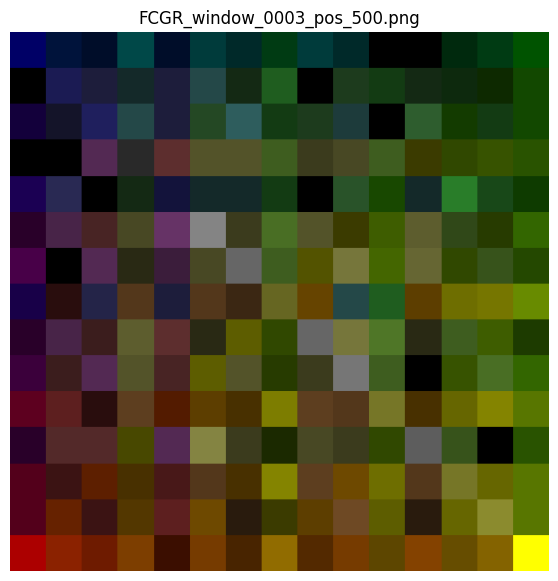

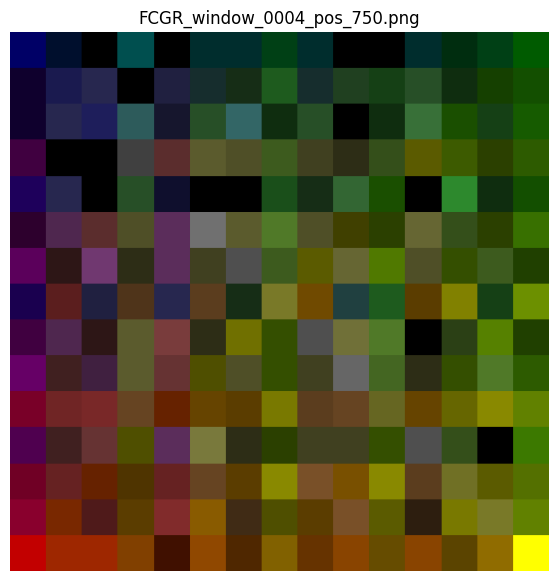

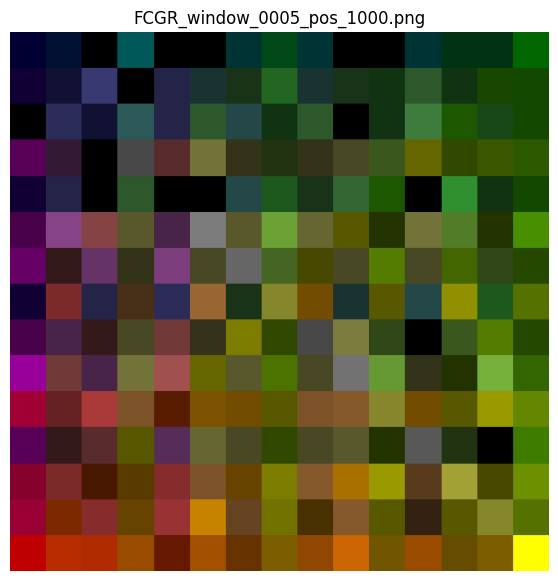

In [132]:
print(
    "\n=========================================="
)

print(
    "DISPLAYING FIRST 5 FCGR IMAGES"
)

print(
    "=========================================="
)


for image_file in image_files[:5]:

    image = Image.open(

        image_file

    )


    plt.figure(

        figsize=(7, 7)

    )


    plt.imshow(

        image

    )


    plt.title(

        image_file.name

    )


    plt.axis(

        "off"

    )


    plt.show()


In [133]:

print("PROCESS COMPLETED")


print("Genome ID:",record.id)
print("Original genome length:",len(sequence))
print("Good windows:", len(windows))
print("K-mer size:", K)
print("Original k-mer features:",len(all_kmers))
print("Selected k-mer features:", len(selected_kmers))
print( "FCGR image size:", f"{2**K} * {2**K}")
print("Saved image size:","512 * 512")
print( "Output folder:", OUTPUT_DIR)
print( "\nFiles generated:")
print("1. kmer_frequency_matrix.csv")
print("2. all_kmer_variance_scores.csv")
print("3. selected_kmers.csv")
print("4. selected_kmer_feature_matrix.csv")
print("5. image_features.csv")
print("6. window_information.csv")
print("7. fcgr_images/")
print("DONE")


PROCESS COMPLETED
Genome ID: JAYEVJ010000043.1
Original genome length: 100000
Good windows: 100
K-mer size: 4
Original k-mer features: 256
Selected k-mer features: 256
FCGR image size: 16 * 16
Saved image size: 512 * 512
Output folder: Melocanna_fasta_fcgr_output

Files generated:
1. kmer_frequency_matrix.csv
2. all_kmer_variance_scores.csv
3. selected_kmers.csv
4. selected_kmer_feature_matrix.csv
5. image_features.csv
6. window_information.csv
7. fcgr_images/
DONE
